In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
df = pd.read_csv("Iris.csv")
print("Shape:", df.shape)
print(df.head())

print(df["Species"].value_counts()) 

Shape: (150, 6)
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [3]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = df[features].values
y_true = df["Species"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled.shape)
print("Means:", X_scaled.mean(axis=0).round(3))
print("Stds :", X_scaled.std(axis=0).round(3))

Scaled data shape: (150, 4)
Means: [-0. -0. -0. -0.]
Stds : [1. 1. 1. 1.]


K =  1  ->  WCSS =   600.00
K =  2  ->  WCSS =   222.36
K =  3  ->  WCSS =   139.82
K =  4  ->  WCSS =   114.09
K =  5  ->  WCSS =    90.85
K =  6  ->  WCSS =    80.04
K =  7  ->  WCSS =    71.05
K =  8  ->  WCSS =    63.36
K =  9  ->  WCSS =    54.05
K = 10  ->  WCSS =    47.41


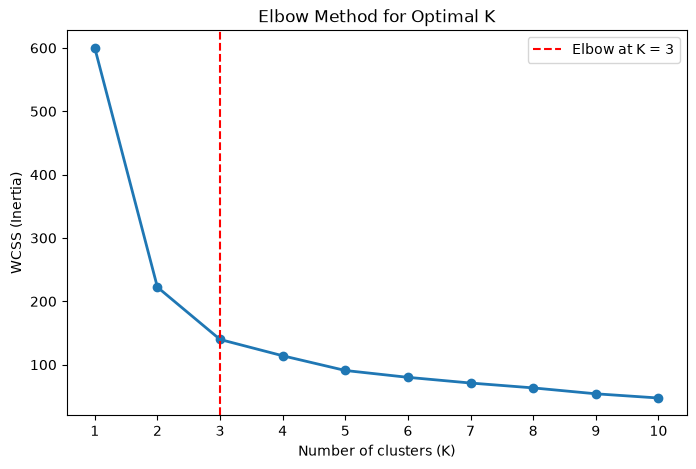

In [4]:
wcss = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    print(f"K = {k:2d}  ->  WCSS = {km.inertia_:8.2f}")

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker="o", linewidth=2)
plt.axvline(3, color="red", linestyle="--", label="Elbow at K = 3")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(K_range)
plt.legend()
plt.show()

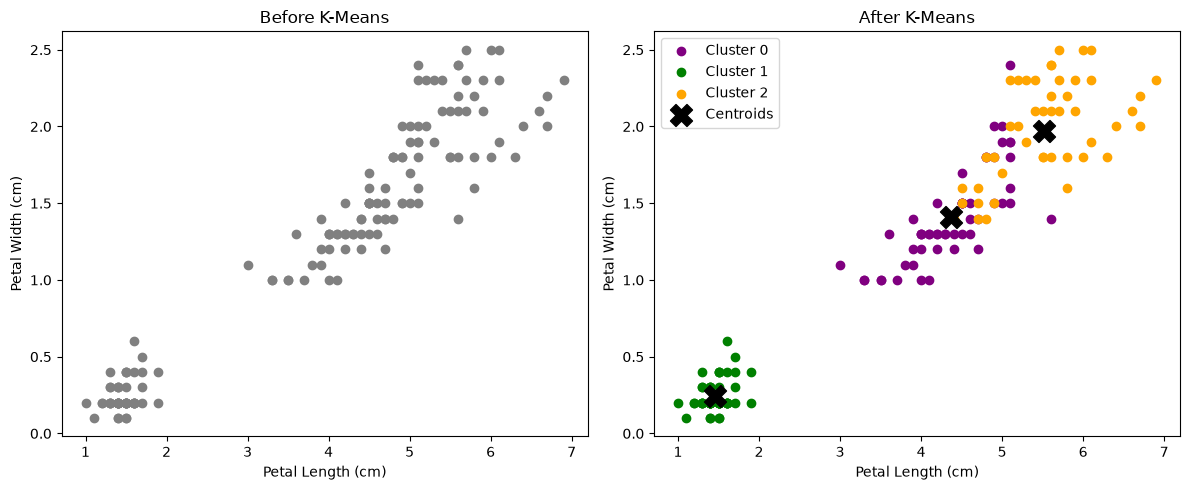

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

x = df["PetalLengthCm"]
y = df["PetalWidthCm"]

ax[0].scatter(x, y, c="grey")
ax[0].set_title("Before K-Means")

colors = ["purple", "green", "orange"]

for k in range(3):
    ax[1].scatter(x[km_labels == k], y[km_labels == k],
                  color=colors[k], label=f"Cluster {k}")

ax[1].scatter(centroids[:, 2], centroids[:, 3],
              c="black", marker="X", s=250, label="Centroids")

ax[1].set_title("After K-Means")

for a in ax:
    a.set_xlabel("Petal Length (cm)")
    a.set_ylabel("Petal Width (cm)")

ax[1].legend()  
plt.tight_layout()
plt.show()

Training: 120 | Testing: 30


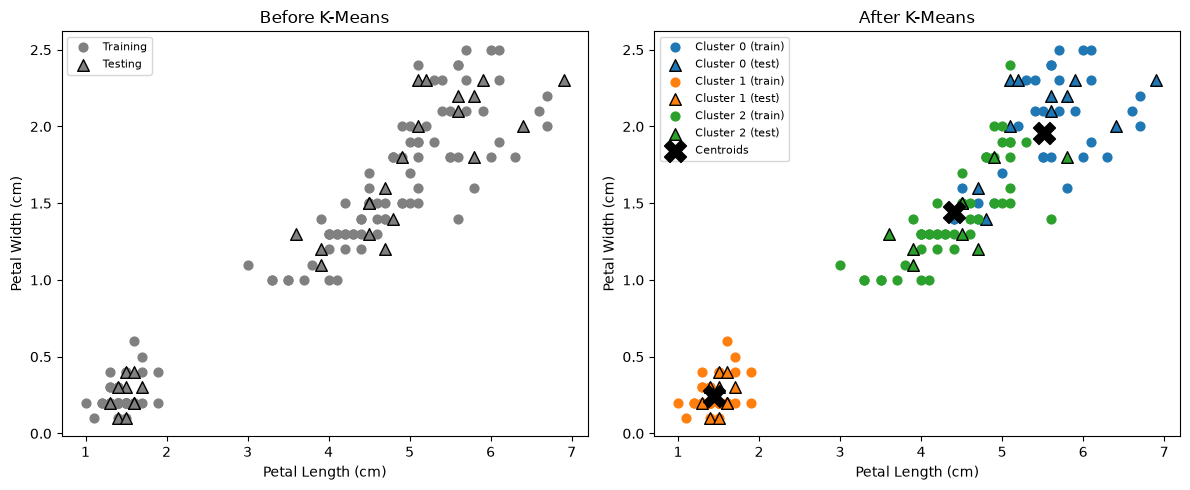

In [6]:
# Split data into 80% training and 20% testing
X_train, X_test, idx_train, idx_test = train_test_split(
    X_scaled, df.index, test_size=0.2, random_state=42
)

# Train K-Means and predict clusters
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
train_labels = kmeans.fit_predict(X_train)
test_labels = kmeans.predict(X_test)

centroids = scaler.inverse_transform(kmeans.cluster_centers_)
train, test = df.loc[idx_train], df.loc[idx_test]

print("Training:", len(train), "| Testing:", len(test))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Before clustering
ax[0].scatter(train.PetalLengthCm, train.PetalWidthCm,
              c="grey", s=40, label="Training")
ax[0].scatter(test.PetalLengthCm, test.PetalWidthCm,
              c="grey", s=70, marker="^", edgecolors="black", label="Testing")

# After clustering
colors = ["tab:blue", "tab:orange", "tab:green"]

for k in range(3):
    tr = train[train_labels == k]
    te = test[test_labels == k]

    ax[1].scatter(tr.PetalLengthCm, tr.PetalWidthCm,
                  color=colors[k], s=40, label=f"Cluster {k} (train)")
    ax[1].scatter(te.PetalLengthCm, te.PetalWidthCm,
                  color=colors[k], s=70, marker="^", edgecolors="black",
                  label=f"Cluster {k} (test)")

# Plot centroids
ax[1].scatter(centroids[:, 2], centroids[:, 3],
              c="black", marker="X", s=250, label="Centroids")

# Titles, labels and legends
for a, title in zip(ax, ["Before K-Means", "After K-Means"]):
    a.set(title=title, xlabel="Petal Length (cm)", ylabel="Petal Width (cm)")
    a.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [7]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10)
km_labels = kmeans.fit_predict(X_scaled)
df["KMeans_Cluster"] = km_labels

print("Silhouette Score:", round(silhouette_score(X_scaled, km_labels), 3))

Silhouette Score: 0.46


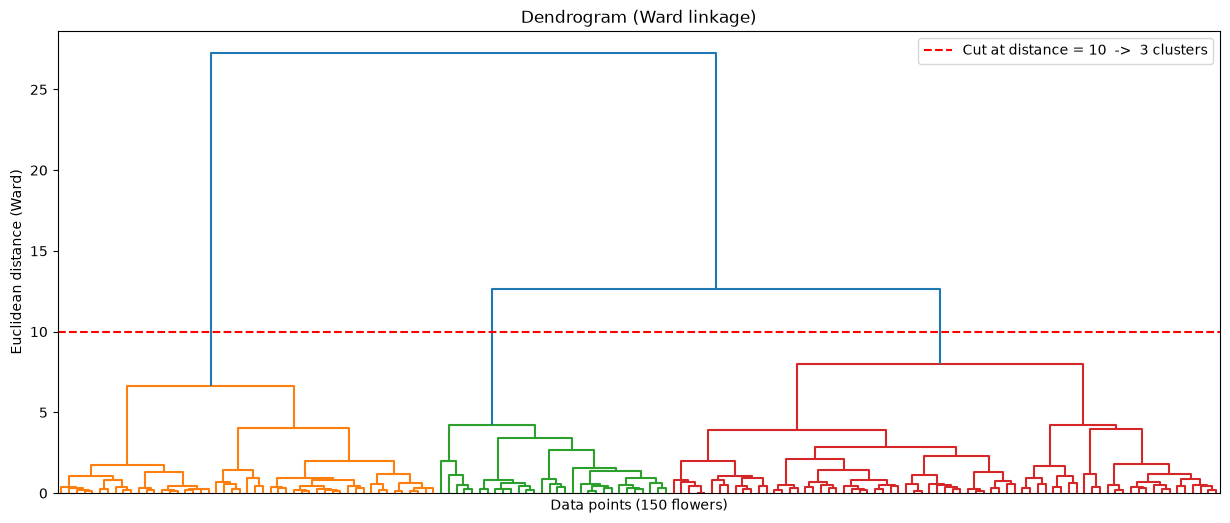

In [8]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(15, 6))
dendrogram(Z, no_labels=True, color_threshold=10)
plt.axhline(y=10, color="red", linestyle="--", label="Cut at distance = 10  ->  3 clusters")
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Data points (150 flowers)")
plt.ylabel("Euclidean distance (Ward)")
plt.legend()
plt.show()

         SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Cluster                                                          
0                 6.55          2.99           5.27          1.85
1                 5.02          3.45           1.47          0.24
2                 5.53          2.57           3.93          1.21


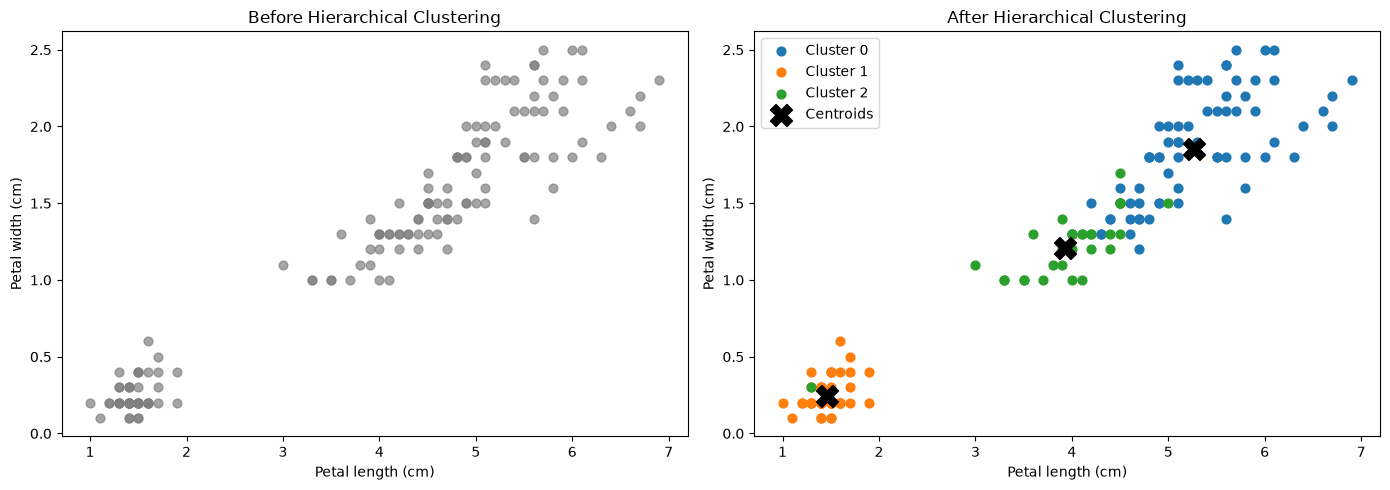

In [9]:
hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(X_scaled)

hc_centroids_cm = []
for k in range(3):
    cluster_points = df.loc[hc_labels == k, features]
    hc_centroids_cm.append(cluster_points.mean().values)
hc_centroids_cm = np.array(hc_centroids_cm)
print(pd.DataFrame(hc_centroids_cm, columns=features).round(2).rename_axis("Cluster"))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(df["PetalLengthCm"], df["PetalWidthCm"], s=40, c="grey", alpha=0.7)
ax[0].set_title("Before Hierarchical Clustering")
ax[0].set_xlabel("Petal length (cm)")
ax[0].set_ylabel("Petal width (cm)")

for k in range(3):
    m = hc_labels == k
    ax[1].scatter(df.loc[m, "PetalLengthCm"], df.loc[m, "PetalWidthCm"],
                  s=40, label=f"Cluster {k}")

ax[1].scatter(hc_centroids_cm[:, 2], hc_centroids_cm[:, 3],
              s=250, c="black", marker="X", label="Centroids")

ax[1].set_title("After Hierarchical Clustering")
ax[1].set_xlabel("Petal length (cm)")
ax[1].set_ylabel("Petal width (cm)")
ax[1].legend()

plt.tight_layout()
plt.show()

         SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Cluster                                                          
0                 5.81          2.71           4.36          1.43
1                 5.00          3.48           1.45          0.24
2                 6.89          3.13           5.64          2.01


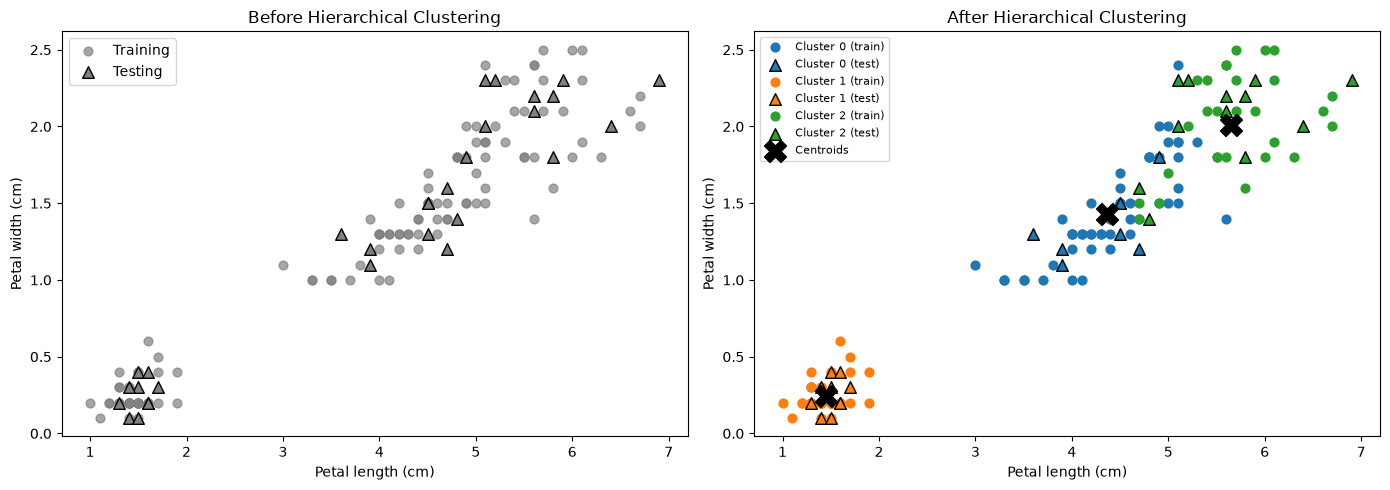

In [10]:
# Fit hierarchical clustering on training points only
hc_tt = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_train_labels = hc_tt.fit_predict(X_train)

# Centroids = mean of the training points in each cluster
hc_centroids_scaled = []
for k in range(3):
    cluster_points = X_train[hc_train_labels == k]
    hc_centroids_scaled.append(cluster_points.mean(axis=0))
hc_centroids_scaled = np.array(hc_centroids_scaled)
hc_centroids_cm = scaler.inverse_transform(hc_centroids_scaled)   # back to cm
print(pd.DataFrame(hc_centroids_cm, columns=features).round(2).rename_axis("Cluster"))

# Assign each testing point to its nearest centroid (no predict() in hierarchical)
# Distances from each test point to each training centroid.
dists = pairwise_distances(X_test, hc_centroids_scaled)
hc_test_labels = dists.argmin(axis=1)

train_pts = df.loc[idx_train]
test_pts = df.loc[idx_test]
colors = ["tab:blue", "tab:orange", "tab:green"]   # one fixed colour per cluster

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Before: raw data (circle = training, triangle = testing)
ax[0].scatter(train_pts["PetalLengthCm"], train_pts["PetalWidthCm"], s=40, c="grey", alpha=0.7, marker="o", label="Training")
ax[0].scatter(test_pts["PetalLengthCm"], test_pts["PetalWidthCm"], s=70, c="grey", edgecolor="black", marker="^", label="Testing")
ax[0].set_title("Before Hierarchical Clustering")
ax[0].legend()

# After: same colour per cluster, circle = training, triangle = testing
for k in range(3):
    tr = train_pts[hc_train_labels == k]
    te = test_pts[hc_test_labels == k]
    ax[1].scatter(tr["PetalLengthCm"], tr["PetalWidthCm"], s=40, color=colors[k], marker="o",
                  label=f"Cluster {k} (train)")
    ax[1].scatter(te["PetalLengthCm"], te["PetalWidthCm"], s=70, color=colors[k], edgecolor="black", marker="^",
                  label=f"Cluster {k} (test)")
ax[1].scatter(hc_centroids_cm[:, 2], hc_centroids_cm[:, 3], s=250, c="black", marker="X", label="Centroids")
ax[1].set_title("After Hierarchical Clustering")
ax[1].legend(fontsize=8)

for a in ax:
    a.set_xlabel("Petal length (cm)")
    a.set_ylabel("Petal width (cm)")

plt.tight_layout()
plt.show()

In [11]:
hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(X_scaled)
df["HC_Cluster"] = hc_labels

print("Silhouette Score:", round(silhouette_score(X_scaled, hc_labels), 3))

Silhouette Score: 0.447


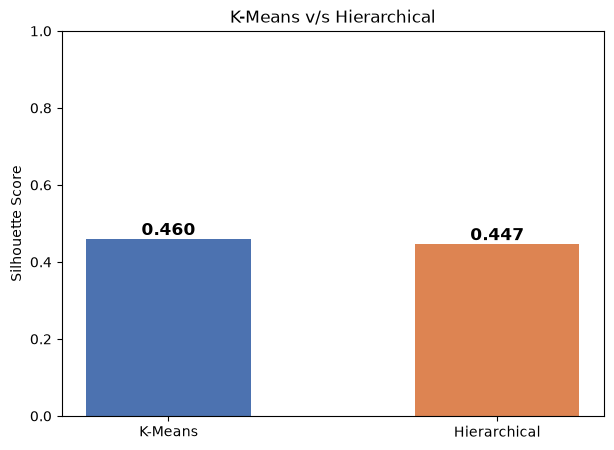

In [12]:
km_sil = silhouette_score(X_scaled, km_labels)
hc_sil = silhouette_score(X_scaled, hc_labels)

models = ["K-Means", "Hierarchical"]
scores = [km_sil, hc_sil]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, scores, color=["#4C72B0", "#DD8452"], width=0.5)

# Write the score on top of each bar
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{score:.3f}", ha="center", fontsize=12, fontweight="bold")

plt.title("K-Means v/s Hierarchical")
plt.ylabel("Silhouette Score")
plt.ylim(0, 1)
plt.show()

K-Means Dunn Index: 0.0265
Hierarchical Dunn Index: 0.0983


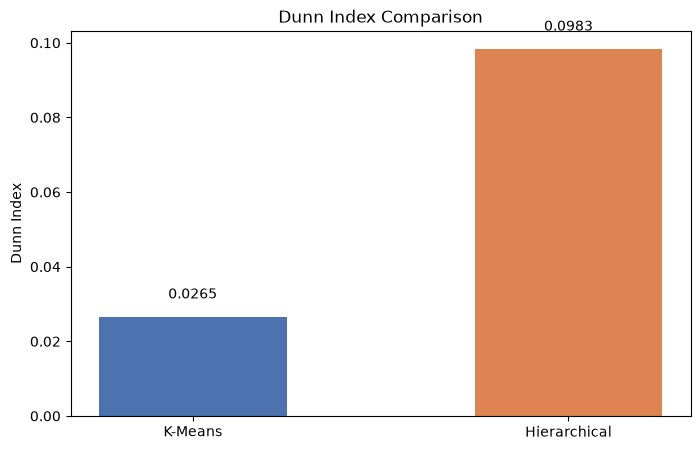

In [13]:
def dunn_index(X, labels):
    distances = pairwise_distances(X)
    clusters = []
    for k in np.unique(labels):
        cluster_indices = np.where(labels == k)[0]
        clusters.append(cluster_indices)

    min_inter = float("inf")
    max_intra = 0

    for i in range(len(clusters)):
        intra = distances[np.ix_(clusters[i], clusters[i])]
        max_intra = max(max_intra, intra.max())

        for j in range(i + 1, len(clusters)):
            inter = distances[np.ix_(clusters[i], clusters[j])]
            min_inter = min(min_inter, inter.min())

    if max_intra > 0:
        return min_inter / max_intra
    else:
        return float("inf")


km_dunn = dunn_index(X_scaled, km_labels)
hc_dunn = dunn_index(X_scaled, hc_labels)

print(f"K-Means Dunn Index: {km_dunn:.4f}")
print(f"Hierarchical Dunn Index: {hc_dunn:.4f}")

models = ["K-Means", "Hierarchical"]
scores = [km_dunn, hc_dunn]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, scores, color=["#4C72B0", "#DD8452"], width=0.5)

for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f"{score:.4f}", ha="center")

plt.title("Dunn Index Comparison")
plt.ylabel("Dunn Index")
plt.show()